In [ ]:
# Sel 1 - Setup Colab & Ekstrak ZIP (Diadaptasi dari CP_NEW_TRAINING.ipynb)
!pip -q install grad-cam imagehash
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile

ZIP_PATH    = '/content/drive/MyDrive/dataset_reorganized.zip'
EXTRACT_DIR = '/content/BaliMask_Clean'

assert os.path.exists(ZIP_PATH), f"❌ ZIP tidak ditemukan: {ZIP_PATH}"

if not os.path.exists(EXTRACT_DIR):
    print("📦 Mengekstrak dataset dari ZIP...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print("✅ Ekstraksi selesai.")
else:
    print("✅ Dataset sudah pernah diekstrak, lanjut.")

# ── Auto-detect struktur folder ──
def find_data_root(base_dir):
    if all(os.path.exists(os.path.join(base_dir, s)) for s in ['train', 'valid', 'test']):
        return base_dir
    for item in os.listdir(base_dir):
        sub = os.path.join(base_dir, item)
        if os.path.isdir(sub) and all(os.path.exists(os.path.join(sub, s)) for s in ['train', 'valid', 'test']):
            return sub
    raise FileNotFoundError(f"Tidak ditemukan struktur train/valid/test di dalam {base_dir}")

DATA_ROOT = find_data_root(EXTRACT_DIR)
print(f"\n✅ DATA_ROOT terdeteksi otomatis: {DATA_ROOT}")

Mounted at /content/drive
📦 Mengekstrak dataset dari ZIP...
✅ Ekstraksi selesai.

✅ DATA_ROOT terdeteksi otomatis: /content/BaliMask_Clean/dataset_reorganized


In [ ]:
# Sel 2 - Import, path, dan konfigurasi global
import os, json, time, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

# ---------- Path (DIUBAH SESUAI DATASET ZIP) ----------
BASE_DIR = Path(DATA_ROOT)

# PENTING: Kita menargetkan folder 'train' di dalam ZIP sebagai DATA_DIR.
# Sebab Sel 3 di VGG16 mengharuskan folder berisi langsung nama kelas (misal: train/barong-ket/*.jpg).
# Jika diarahkan ke BASE_DIR, VGG16 akan mengira 'train', 'test', 'valid' adalah nama kelas topeng.
DATA_DIR = BASE_DIR / "train"
REAL_DIR = BASE_DIR / "real_world"    # OPSIONAL: foto sendiri, tidak dipakai training (struktur sama)

# Output disimpan ke Google Drive agar tidak hilang saat Colab terputus
OUT_ROOT = Path("/content/drive/MyDrive/BaliMask_Clean/outputs_vgg16")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# ---------- Pengaturan umum: SAMAKAN di semua notebook agar perbandingan adil ----------
SPLIT_SEED = 42                # seed pembagian data, TETAP (jangan diubah antar-model)
SEEDS = [42, 123, 2024]        # seed training -> dilaporkan mean +- std; pakai [42] jika waktu mepet
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True       # bobot kelas pada loss untuk dataset tidak seimbang
USE_AMP = True                 # mixed precision (hemat memori & lebih cepat di GPU T4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Device: cuda | Tesla T4


In [ ]:
# Sel 3 - Scan dataset, deteksi duplikat (pHash), dan split bebas kebocoran (data leakage)
import imagehash
from sklearn.model_selection import StratifiedGroupKFold

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_CSV = OUT_ROOT / "split.csv"      # dibuat SEKALI lalu dipakai semua model. Hapus jika dataset berubah.

def scan_folder(root):
    root = Path(root)
    classes = sorted([d.name for d in root.iterdir() if d.is_dir()])
    rows = []
    for ci, c in enumerate(classes):
        for p in sorted((root / c).rglob("*")):
            if p.suffix.lower() in IMG_EXT:
                rows.append((str(p.relative_to(root)), c, ci))
    return classes, pd.DataFrame(rows, columns=["path", "label", "y"])

def phash_groups(df, root, max_dist=4):
    # Gambar dengan jarak Hamming pHash <= max_dist dianggap duplikat / near-duplicate
    # (mis. hasil augmentasi offline atau foto yang nyaris sama) dan dimasukkan ke SATU grup,
    # sehingga satu grup tidak akan terpecah ke train dan test.
    hashes = []
    for p in tqdm(df.path, desc="pHash"):
        with Image.open(Path(root) / p) as im:
            hashes.append(imagehash.phash(im.convert("RGB")).hash.flatten())
    arr = np.array(hashes, dtype=np.uint8)
    n = len(arr)
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i in range(n - 1):
        d = (arr[i + 1:] != arr[i]).sum(axis=1)
        for j in np.where(d <= max_dist)[0]:
            ra, rb = find(i), find(i + 1 + int(j))
            if ra != rb:
                parent[rb] = ra
    return np.array([find(i) for i in range(n)])

def make_split(df, groups, seed=SPLIT_SEED):
    # Kurang lebih 64% train / 16% val / 20% test, stratified per kelas dan per grup.
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trval_idx, test_idx = next(sgkf.split(df, df.y, groups))
    sub = df.iloc[trval_idx]
    sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    _, va_rel = next(sgkf2.split(sub, sub.y, groups[trval_idx]))
    split = np.full(len(df), "train", dtype=object)
    split[trval_idx[va_rel]] = "val"
    split[test_idx] = "test"
    out = df.copy()
    out["group"] = groups
    out["split"] = split
    return out

if SPLIT_CSV.exists():
    df = pd.read_csv(SPLIT_CSV)
    print("Memuat split yang sudah ada:", SPLIT_CSV)
else:
    _, df = scan_folder(DATA_DIR)
    assert len(df) > 0, f"Tidak ada gambar di {DATA_DIR}"
    groups = phash_groups(df, DATA_DIR)
    print(f"Total gambar: {len(df)} | grup unik: {len(set(groups))} | "
          f"gambar yang masuk grup duplikat: {len(df) - len(set(groups))}")
    df = make_split(df, groups)
    df.to_csv(SPLIT_CSV, index=False)
    print("Split disimpan ke", SPLIT_CSV)

CLASSES = df.drop_duplicates("y").sort_values("y").label.tolist()
NUM_CLASSES = len(CLASSES)
json.dump(CLASSES, open(OUT_ROOT / "classes.json", "w"), ensure_ascii=False, indent=2)   # dipakai API nanti
assert df.groupby("group").split.nunique().max() == 1, "Ada grup duplikat yang bocor antar-split!"
print(f"{NUM_CLASSES} kelas:", CLASSES)
display(pd.crosstab(df.label, df.split)[["train", "val", "test"]])

pHash:   0%|          | 0/3380 [00:00<?, ?it/s]

Total gambar: 3380 | grup unik: 2163 | gambar yang masuk grup duplikat: 1217
Split disimpan ke /content/drive/MyDrive/BaliMask_Clean/outputs_vgg16/split.csv
13 kelas: ['barong-bangkal', 'barong-ket', 'bujuh', 'dalem', 'jauk-keras', 'jauk-manis', 'keras', 'macan', 'penasar', 'sidakarya', 'telek', 'tua', 'wijil']


split,train,val,test
label,,,
barong-bangkal,173,31,56
barong-ket,170,37,53
bujuh,160,45,55
dalem,168,51,41
jauk-keras,167,36,57
jauk-manis,160,43,57
keras,173,35,52
macan,162,46,52
penasar,157,55,48


In [ ]:
# Sel 4 - Transform, Dataset, DataLoader, dan test set "dunia nyata" (opsional)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(),          # nonaktifkan jika ada kelas yang hanya beda karena orientasi
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])
eval_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
base_tf = transforms.Compose([                  # untuk overlay Grad-CAM (tanpa normalisasi)
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
])

class MaskDS(Dataset):
    def __init__(self, frame, root, tf):
        self.paths = [Path(root) / p for p in frame.path]
        self.y = frame.y.values.astype(int)
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), int(self.y[i])

def make_loader(frame, root, tf, shuffle, seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(
        MaskDS(frame, root, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
        generator=g if shuffle else None,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=lambda w: np.random.seed(seed + w),
    )

def load_real_df():
    # Foto yang kalian ambil sendiri (sanggar/museum/toko), TIDAK ikut training -> uji generalisasi nyata.
    if not REAL_DIR.exists():
        return None
    _, d = scan_folder(REAL_DIR)
    d = d[d.label.isin(CLASSES)].copy()
    if len(d) == 0:
        return None
    d["y"] = d.label.map({c: i for i, c in enumerate(CLASSES)})
    return d.reset_index(drop=True)

df_real = load_real_df()
print("Real-world test set:", "tidak ada" if df_real is None else f"{len(df_real)} gambar")

Real-world test set: tidak ada


In [ ]:
# Sel 5 - Evaluasi, efisiensi (parameter/FLOPs/latensi), confusion matrix, dan Grad-CAM
from torch.utils.flop_counter import FlopCounterMode

def plot_cm(cm, path):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    s = max(6, NUM_CLASSES * 0.7)
    fig, axes = plt.subplots(1, 2, figsize=(2 * s + 2, s))
    for ax, M, title, fmt in [(axes[0], cm, "Jumlah", "d"), (axes[1], cmn, "Dinormalisasi per kelas (recall)", ".2f")]:
        ax.imshow(M, cmap="Blues")
        ax.set_title(title)
        ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
        ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
        ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
        if NUM_CLASSES <= 15:
            for i in range(NUM_CLASSES):
                for j in range(NUM_CLASSES):
                    v = int(M[i, j]) if fmt == "d" else float(M[i, j])
                    ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                            color="white" if M[i, j] > M.max() / 2 else "black")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.close(fig)

def evaluate_and_save(out_dir, frame, probs, prefix):
    # probs: (N, C) probabilitas softmax; frame: dataframe sampel (path, y)
    y = frame.y.values
    pred = probs.argmax(1)
    conf = probs.max(1)
    labels = list(range(NUM_CLASSES))
    rep = classification_report(y, pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(rep).T.to_csv(out_dir / f"report_{prefix}.csv")
    cm = confusion_matrix(y, pred, labels=labels)
    plot_cm(cm, out_dir / f"confusion_{prefix}.png")
    top3 = np.argsort(-probs, axis=1)[:, :3]
    pd.DataFrame({
        "path": frame.path.values,
        "true": [CLASSES[i] for i in y],
        "pred": [CLASSES[i] for i in pred],
        "conf": conf.round(4),
        "benar": (y == pred),
        "top3": ["|".join(CLASSES[k] for k in row) for row in top3],
    }).to_csv(out_dir / f"predictions_{prefix}.csv", index=False)
    pairs = sorted([(CLASSES[i], CLASSES[j], int(cm[i, j]))
                    for i in labels for j in labels if i != j and cm[i, j] > 0], key=lambda t: -t[2])[:5]
    return dict(
        acc=float(accuracy_score(y, pred)),
        macro_f1=float(f1_score(y, pred, average="macro", zero_division=0)),
        weighted_f1=float(f1_score(y, pred, average="weighted", zero_division=0)),
        macro_precision=float(precision_score(y, pred, average="macro", zero_division=0)),
        macro_recall=float(recall_score(y, pred, average="macro", zero_division=0)),
        top_confusions=pairs,
    )

def plot_history(hist, path, n_head):
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(h.train_loss, label="train"); ax[0].plot(h.val_loss, label="val"); ax[0].set_title("Loss")
    ax[1].plot(h.train_acc, label="train"); ax[1].plot(h.val_acc, label="val"); ax[1].set_title("Akurasi")
    ax[2].plot(h.val_f1, label="val macro-F1"); ax[2].set_title("Macro-F1 (validasi)")
    for a in ax:
        a.axvline(n_head - 0.5, color="gray", linestyle="--", linewidth=1)   # batas fase 1 (head) -> fase 2 (full)
        a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.close(fig)

def count_params_m(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

@torch.no_grad()
def measure_gflops(model):
    model.eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=next(model.parameters()).device)
    with FlopCounterMode(display=False) as fc:
        model(x)
    return fc.get_total_flops() / 1e9          # FLOPs = 2 x MAC

@torch.no_grad()
def measure_latency_ms(model, dev, n_warm=10, n_run=50):
    model.eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=dev)
    for _ in range(n_warm):
        model(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n_run):
        model(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t) / n_run * 1000.0

def gradcam_grid(model, target_layer, frame, probs, out_path, n_wrong=8, n_right=4, seed=0):
    # Menampilkan area yang diperhatikan model: prediksi SALAH (paling yakin dulu) dan beberapa BENAR.
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    for m in model.modules():
        if hasattr(m, "inplace"):
            m.inplace = False                  # inplace op merusak hook backward Grad-CAM
    model.eval()
    y = frame.y.values
    pred = probs.argmax(1)
    conf = probs.max(1)
    wrong = np.where(pred != y)[0]
    wrong = wrong[np.argsort(-conf[wrong])][:n_wrong]
    right = np.where(pred == y)[0]
    rng = np.random.RandomState(seed)
    right = rng.choice(right, size=min(n_right, len(right)), replace=False) if len(right) else []
    picks = [(int(i), "SALAH") for i in wrong] + [(int(i), "BENAR") for i in right]
    if not picks:
        return
    cols = 4
    rows = int(np.ceil(len(picks) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.4 * rows))
    axes = np.atleast_1d(axes).ravel()
    with GradCAM(model=model, target_layers=[target_layer]) as cam:
        for ax, (i, tg) in zip(axes, picks):
            img = Image.open(DATA_DIR / frame.path.iloc[i]).convert("RGB")
            rgb = np.asarray(base_tf(img), dtype=np.float32) / 255.0
            x = eval_tf(img).unsqueeze(0).to(next(model.parameters()).device)
            g = cam(input_tensor=x, targets=[ClassifierOutputTarget(int(pred[i]))])[0]
            ax.imshow(show_cam_on_image(rgb, g, use_rgb=True))
            ax.axis("off")
            ax.set_title(f"[{tg}] asli: {CLASSES[y[i]]}\nprediksi: {CLASSES[pred[i]]} ({conf[i]:.2f})",
                         fontsize=9, color="red" if tg == "SALAH" else "green")
    for ax in axes[len(picks):]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(out_path, dpi=150); plt.close(fig)

In [ ]:
# Sel 6 - Fungsi training (fase 1: head; fase 2: fine-tune seluruh jaringan) - identik di semua model
def set_frozen(params, frozen):
    for p in params:
        p.requires_grad = not frozen

def enter_train_mode(model):
    # BatchNorm yang parameternya dibekukan dikunci ke mode eval agar running-stat pretrained tidak rusak.
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            ps = list(m.parameters(recurse=False))
            if ps and not any(p.requires_grad for p in ps):
                m.eval()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    if train:
        enter_train_mode(model)
    else:
        model.eval()
    tot, n = 0.0, 0
    all_p, all_y = [], []
    amp_on = USE_AMP and device.type == "cuda"
    with (torch.enable_grad() if train else torch.no_grad()):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
            tot += loss.item() * x.size(0)
            n += x.size(0)
            all_p.append(logits.argmax(1).cpu())
            all_y.append(y.cpu())
    p = torch.cat(all_p).numpy()
    yy = torch.cat(all_y).numpy()
    return tot / n, accuracy_score(yy, p), f1_score(yy, p, average="macro", zero_division=0)

@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    P = []
    amp_on = USE_AMP and device.type == "cuda"
    for x, _ in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            logits = model(x.to(device, non_blocking=True))
        P.append(torch.softmax(logits.float(), dim=1).cpu())
    return torch.cat(P).numpy()

def train_one(tag, cfg, seed):
    out_dir = OUT_ROOT / tag / f"seed_{seed}"
    out_dir.mkdir(parents=True, exist_ok=True)
    if (out_dir / "metrics.json").exists():                      # tahan putus koneksi Colab
        print(f"[{tag}] seed {seed} sudah selesai -> dilewati")
        return json.load(open(out_dir / "metrics.json"))

    set_seed(seed)
    tr_df, va_df, te_df = [df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]
    tr_loader = make_loader(tr_df, DATA_DIR, train_tf, True, seed)
    va_loader = make_loader(va_df, DATA_DIR, eval_tf, False)
    te_loader = make_loader(te_df, DATA_DIR, eval_tf, False)

    model = cfg["build"](NUM_CLASSES).to(device)
    bb, hd = cfg["groups"](model)                                # (parameter backbone, parameter head/baru)

    if USE_CLASS_WEIGHTS:
        cnt = np.bincount(tr_df.y, minlength=NUM_CLASSES).astype(np.float32)
        w = torch.tensor(cnt.sum() / (NUM_CLASSES * np.maximum(cnt, 1)), device=device)
    else:
        w = None
    criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=LABEL_SMOOTHING)
    scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and device.type == "cuda"))

    json.dump({"tag": tag, "seed": seed, "img_size": IMG_SIZE, "batch_size": BATCH_SIZE,
               "label_smoothing": LABEL_SMOOTHING, "class_weights": USE_CLASS_WEIGHTS, "amp": USE_AMP,
               **{k: v for k, v in cfg.items() if not callable(v)}},
              open(out_dir / "config.json", "w"), indent=2)

    hist = []
    best = dict(f1=-1.0, loss=1e9, epoch=-1, state=None)
    t0 = time.time()

    def after_epoch(phase, ep, lr, tr, va):
        row = dict(phase=phase, epoch=len(hist), lr=lr, train_loss=tr[0], train_acc=tr[1],
                   val_loss=va[0], val_acc=va[1], val_f1=va[2])
        hist.append(row)
        improved = (va[2] > best["f1"] + 1e-4) or (abs(va[2] - best["f1"]) <= 1e-4 and va[0] < best["loss"])
        if improved:
            best.update(f1=va[2], loss=va[0], epoch=row["epoch"],
                        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        print(f"[{tag}|s{seed}|{phase}] ep{row['epoch']:02d} lr={lr:.2e} "
              f"loss {tr[0]:.4f}/{va[0]:.4f} acc {tr[1]:.3f}/{va[1]:.3f} valF1 {va[2]:.3f}"
              f"{'  *best*' if improved else ''}")
        return improved

    # ---- Fase 1: backbone dibekukan, hanya head (dan modul baru) yang dilatih ----
    set_frozen(bb, True)
    opt = torch.optim.AdamW(hd, lr=cfg["lr_head"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(cfg["epochs_head"], 1))
    for ep in range(cfg["epochs_head"]):
        lr = opt.param_groups[0]["lr"]
        tr = run_epoch(model, tr_loader, criterion, opt, scaler)
        va = run_epoch(model, va_loader, criterion)
        after_epoch("head", ep, lr, tr, va)
        sched.step()

    # ---- Fase 2: seluruh jaringan di-fine-tune (LR backbone < LR head) + early stopping ----
    set_frozen(bb, False)
    opt = torch.optim.AdamW([{"params": bb, "lr": cfg["lr_bb"]},
                             {"params": hd, "lr": cfg["lr_head_ft"]}], weight_decay=cfg["wd"])
    warm = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=1)
    cos = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(cfg["epochs_fine"] - 1, 1))
    sched = torch.optim.lr_scheduler.SequentialLR(opt, [warm, cos], milestones=[1])
    bad = 0
    for ep in range(cfg["epochs_fine"]):
        lr = opt.param_groups[0]["lr"]
        tr = run_epoch(model, tr_loader, criterion, opt, scaler)
        va = run_epoch(model, va_loader, criterion)
        bad = 0 if after_epoch("full", ep, lr, tr, va) else bad + 1
        sched.step()
        if bad >= cfg["patience"]:
            print(f"[{tag}|s{seed}] early stopping (tidak membaik {cfg['patience']} epoch)")
            break
    train_min = (time.time() - t0) / 60

    # ---- Evaluasi model terbaik ----
    model.load_state_dict(best["state"])
    ckpt = out_dir / "best.pt"
    torch.save(best["state"], ckpt)
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    plot_history(hist, out_dir / "curves.png", cfg["epochs_head"])

    probs = predict_probs(model, te_loader)
    res = evaluate_and_save(out_dir, te_df, probs, "test")
    real = None
    if df_real is not None:
        probs_real = predict_probs(model, make_loader(df_real, REAL_DIR, eval_tf, False))
        real = evaluate_and_save(out_dir, df_real, probs_real, "real")

    cpu_model = copy.deepcopy(model).cpu()
    metrics = dict(
        tag=tag, seed=seed, best_epoch=best["epoch"], val_macro_f1=float(best["f1"]),
        test_acc=res["acc"], test_macro_f1=res["macro_f1"], test_weighted_f1=res["weighted_f1"],
        test_macro_precision=res["macro_precision"], test_macro_recall=res["macro_recall"],
        top_confusions=res["top_confusions"],
        real_acc=None if real is None else real["acc"],
        real_macro_f1=None if real is None else real["macro_f1"],
        params_m=count_params_m(model), size_mb=os.path.getsize(ckpt) / 1e6,
        gflops=measure_gflops(cpu_model),
        latency_gpu_ms=measure_latency_ms(model, device) if device.type == "cuda" else None,
        latency_cpu_ms=measure_latency_ms(cpu_model, torch.device("cpu"), n_warm=3, n_run=20),
        train_minutes=train_min,
    )
    print(f"[{tag}|s{seed}] TEST acc={metrics['test_acc']:.4f} macroF1={metrics['test_macro_f1']:.4f} "
          f"| params={metrics['params_m']:.2f}M size={metrics['size_mb']:.1f}MB "
          f"GFLOPs={metrics['gflops']:.2f} | top kebingungan: {res['top_confusions'][:3]}")

    try:                                                         # Grad-CAM paling akhir
        gradcam_grid(model, cfg["cam_layer"](model), te_df, probs, out_dir / "gradcam.png")
    except Exception as e:
        print("Grad-CAM dilewati:", repr(e))

    json.dump(metrics, open(out_dir / "metrics.json", "w"), indent=2)
    del model, cpu_model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics

def run_experiments(names):
    for tag in names:
        rows = [train_one(tag, EXPERIMENTS[tag], s) for s in SEEDS]
        d = pd.DataFrame(rows)
        cols = ["test_acc", "test_macro_f1", "test_weighted_f1"]
        summ = d[cols].agg(["mean", "std"]).round(4)
        summ.to_csv(OUT_ROOT / tag / "summary.csv")
        print(f"\n===== {tag}: ringkasan {len(rows)} seed =====")
        display(summ)

In [ ]:
# Sel 7 - Definisi model VGG16 (baseline klasik) + hyperparameter
def build_vgg16(num_classes):
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    m.classifier[6] = nn.Linear(4096, num_classes)          # ganti layer output 1000 -> jumlah kelas topeng
    return m

def groups_vgg16(model):
    # (backbone pretrained, head). Pada VGG16 "head" = seluruh classifier (3 layer FC).
    return list(model.features.parameters()), list(model.classifier.parameters())

EXPERIMENTS = {
    "vgg16": dict(
        build=build_vgg16, groups=groups_vgg16,
        cam_layer=lambda m: m.features[-2],                 # ReLU setelah conv5_3 (conv terakhir)
        lr_head=1e-3, lr_bb=1e-5, lr_head_ft=1e-4, wd=1e-4,
        epochs_head=5, epochs_fine=25, patience=6,
    ),
}
# Catatan: VGG16 tanpa BatchNorm sehingga LR backbone dibuat kecil (1e-5) agar stabil.

VGG16 32 menit training

In [ ]:
# Sel 8 - Jalankan training (tiap seed otomatis dilewati jika sudah selesai)
run_experiments(["vgg16"])

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 68.6MB/s]


[vgg16|s42|head] ep00 lr=1.00e-03 loss 1.8284/0.9345 acc 0.564/0.913 valF1 0.901  *best*
[vgg16|s42|head] ep01 lr=9.05e-04 loss 1.0845/0.7522 acc 0.841/0.965 valF1 0.963  *best*
[vgg16|s42|head] ep02 lr=6.55e-04 loss 0.9239/0.7498 acc 0.901/0.976 valF1 0.975  *best*
[vgg16|s42|head] ep03 lr=3.45e-04 loss 0.8120/0.6421 acc 0.955/0.993 valF1 0.991  *best*
[vgg16|s42|head] ep04 lr=9.55e-05 loss 0.7451/0.6271 acc 0.980/0.994 valF1 0.994  *best*
[vgg16|s42|full] ep05 lr=1.00e-06 loss 0.7346/0.6208 acc 0.977/0.994 valF1 0.994  *best*
[vgg16|s42|full] ep06 lr=1.00e-05 loss 0.7116/0.6198 acc 0.986/0.996 valF1 0.995  *best*
[vgg16|s42|full] ep07 lr=9.96e-06 loss 0.6848/0.5958 acc 0.989/0.994 valF1 0.994
[vgg16|s42|full] ep08 lr=9.83e-06 loss 0.6651/0.6019 acc 0.992/0.996 valF1 0.995  *best*
[vgg16|s42|full] ep09 lr=9.62e-06 loss 0.6525/0.5954 acc 0.994/0.994 valF1 0.994
[vgg16|s42|full] ep10 lr=9.33e-06 loss 0.6441/0.5880 acc 0.995/0.993 valF1 0.992
[vgg16|s42|full] ep11 lr=8.97e-06 loss 0.6358

,test_acc,test_macro_f1,test_weighted_f1
mean,0.9986,0.9985,0.9986
std,0.0000,0.0001,0.0000


,n_seed,Akurasi test,Macro-F1 test,Akurasi real-world,Params (M),Ukuran (MB),GFLOPs,Latensi GPU (ms),Latensi CPU (ms)
tag,,,,,,,,,
vgg16,3,0.9986 +- 0.0000,0.9985 +- 0.0001,-,134.31,537.3,30.93,17.11,456.1


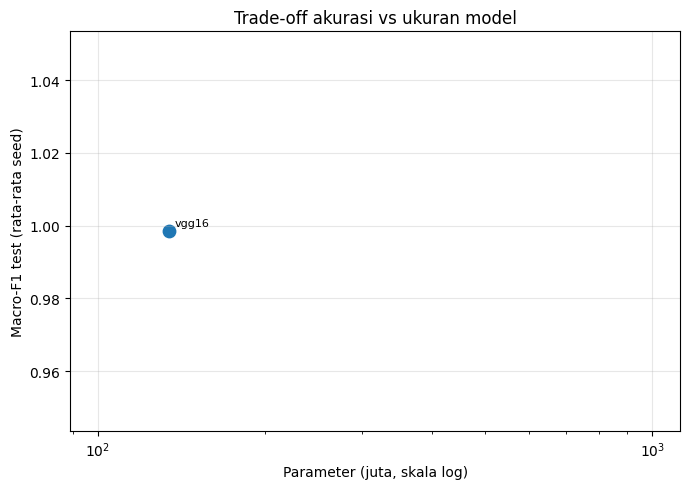

,n_seed,Akurasi test,Macro-F1 test,Akurasi real-world,Params (M),Ukuran (MB),GFLOPs,Latensi GPU (ms),Latensi CPU (ms)
tag,,,,,,,,,
vgg16,3,0.9986 +- 0.0000,0.9985 +- 0.0001,-,134.31,537.3,30.93,17.11,456.1


In [ ]:
# Sel 9 - Rekap semua model yang sudah selesai (bisa dijalankan kapan saja; membaca semua metrics.json)
def rekap_semua_model():
    rows = [json.load(open(f)) for f in sorted(OUT_ROOT.glob("*/seed_*/metrics.json"))]
    if not rows:
        print("Belum ada hasil.")
        return None
    d = pd.DataFrame(rows)
    for c in ["real_acc", "latency_gpu_ms"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    def ms(s):
        s = s.dropna()
        if len(s) == 0:
            return "-"
        return f"{s.mean():.4f} +- {s.std(ddof=1):.4f}" if len(s) > 1 else f"{s.mean():.4f}"
    g = d.groupby("tag")
    table = pd.DataFrame({
        "n_seed": g.size(),
        "Akurasi test": g.test_acc.apply(ms),
        "Macro-F1 test": g.test_macro_f1.apply(ms),
        "Akurasi real-world": g.real_acc.apply(ms),
        "Params (M)": g.params_m.first().round(2),
        "Ukuran (MB)": g.size_mb.first().round(1),
        "GFLOPs": g.gflops.first().round(2),
        "Latensi GPU (ms)": g.latency_gpu_ms.mean().round(2),
        "Latensi CPU (ms)": g.latency_cpu_ms.mean().round(1),
    })
    table.to_csv(OUT_ROOT / "rekap_model.csv")
    display(table)
    f1 = g.test_macro_f1.mean()
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(g.params_m.first(), f1, s=80)
    for tag_ in f1.index:
        ax.annotate(tag_, (g.params_m.first()[tag_], f1[tag_]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("Parameter (juta, skala log)"); ax.set_ylabel("Macro-F1 test (rata-rata seed)")
    ax.set_title("Trade-off akurasi vs ukuran model"); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT_ROOT / "akurasi_vs_parameter.png", dpi=150); plt.show()
    return table

rekap_semua_model()